In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet
from sklearn.metrics import mean_squared_error

In [2]:
df_train=pd.read_csv(r"C:\Users\bisha\Downloads\DailyDelhiClimateTrain.csv")
df_test=pd.read_csv(r"C:\Users\bisha\Downloads\DailyDelhiClimateTest.csv")
df=df_train
df.head()

,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


## univariate forecasting

In [3]:
df_train=df_train.rename(columns={'meantemp':'y','date':'ds'})
df_train['y_orig']=df_train['y']
df_train['y']=np.log(df_train['y'])

In [4]:
model=Prophet()
model.fit(df_train)

00:24:40 - cmdstanpy - INFO - Chain [1] start processing
00:24:40 - cmdstanpy - INFO - Chain [1] done processing


In [5]:
future_data=model.make_future_dataframe(periods=113,freq='D')
forecast_data=model.predict(future_data)
forecast_data.head()

,ds,trend,yhat_lower,yhat_upper,trend_lower,trend_upper,additive_terms,additive_terms_lower,additive_terms_upper,weekly,weekly_lower,weekly_upper,yearly,yearly_lower,yearly_upper,multiplicative_terms,multiplicative_terms_lower,multiplicative_terms_upper,yhat
0,2013-01-01,3.051742,2.266529,2.513614,3.051742,3.051742,-0.660064,-0.660064,-0.660064,0.003585,0.003585,0.003585,-0.663649,-0.663649,-0.663649,0.0,0.0,0.0,2.391678
1,2013-01-02,3.052793,2.277899,2.523231,3.052793,3.052793,-0.655078,-0.655078,-0.655078,0.006954,0.006954,0.006954,-0.662031,-0.662031,-0.662031,0.0,0.0,0.0,2.397715
2,2013-01-03,3.053843,2.275796,2.529134,3.053843,3.053843,-0.655527,-0.655527,-0.655527,0.003641,0.003641,0.003641,-0.659168,-0.659168,-0.659168,0.0,0.0,0.0,2.398315
3,2013-01-04,3.054893,2.286504,2.519213,3.054893,3.054893,-0.653998,-0.653998,-0.653998,0.001182,0.001182,0.001182,-0.655180,-0.655180,-0.655180,0.0,0.0,0.0,2.400895
4,2013-01-05,3.055943,2.283983,2.533785,3.055943,3.055943,-0.654816,-0.654816,-0.654816,-0.004622,-0.004622,-0.004622,-0.650194,-0.650194,-0.650194,0.0,0.0,0.0,2.401127


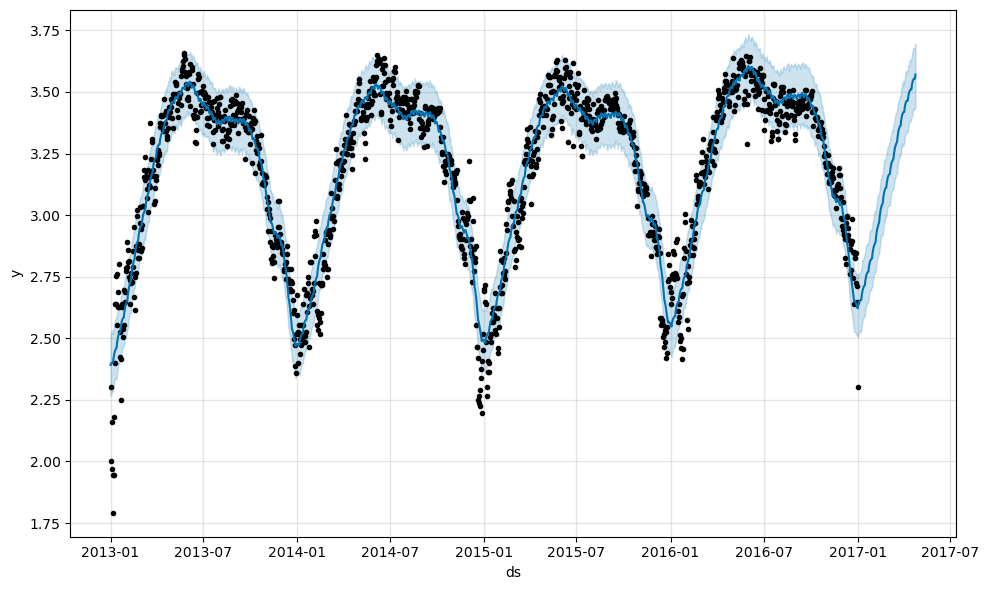

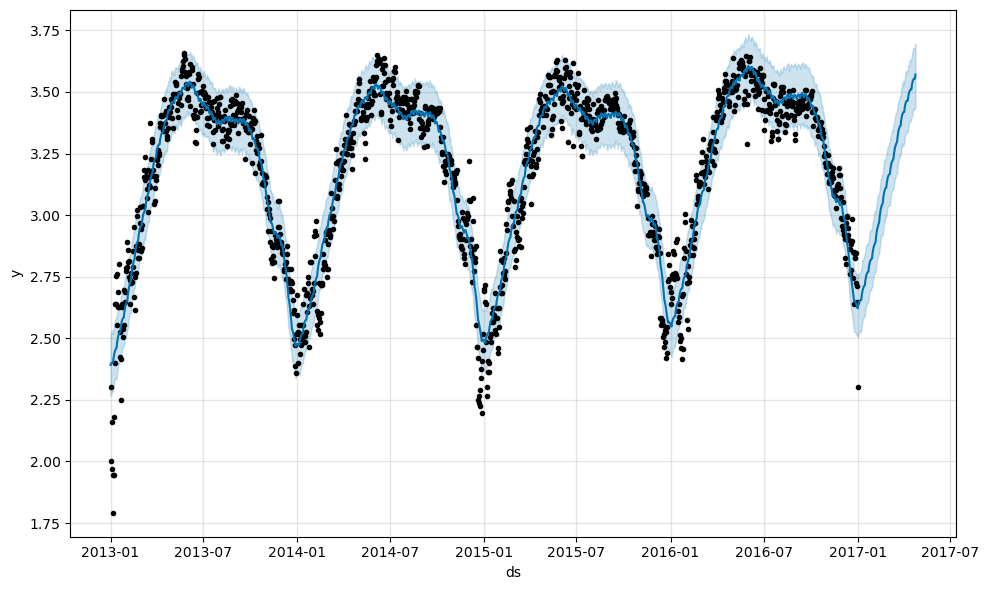

In [6]:
model.plot(forecast_data)

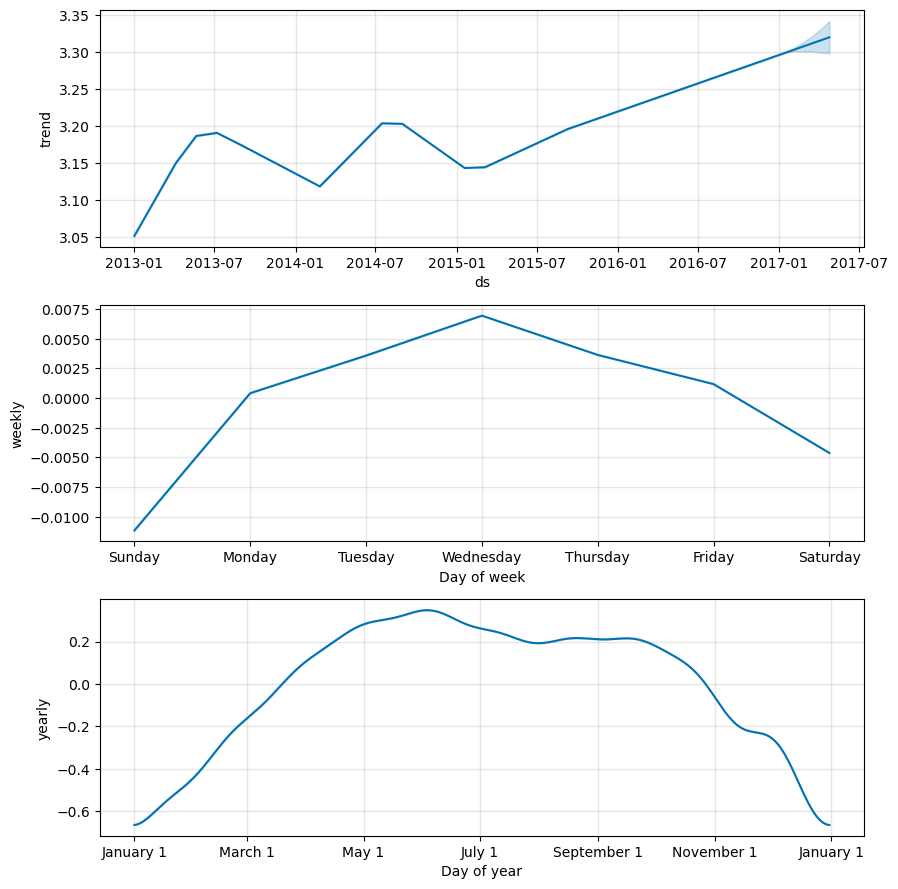

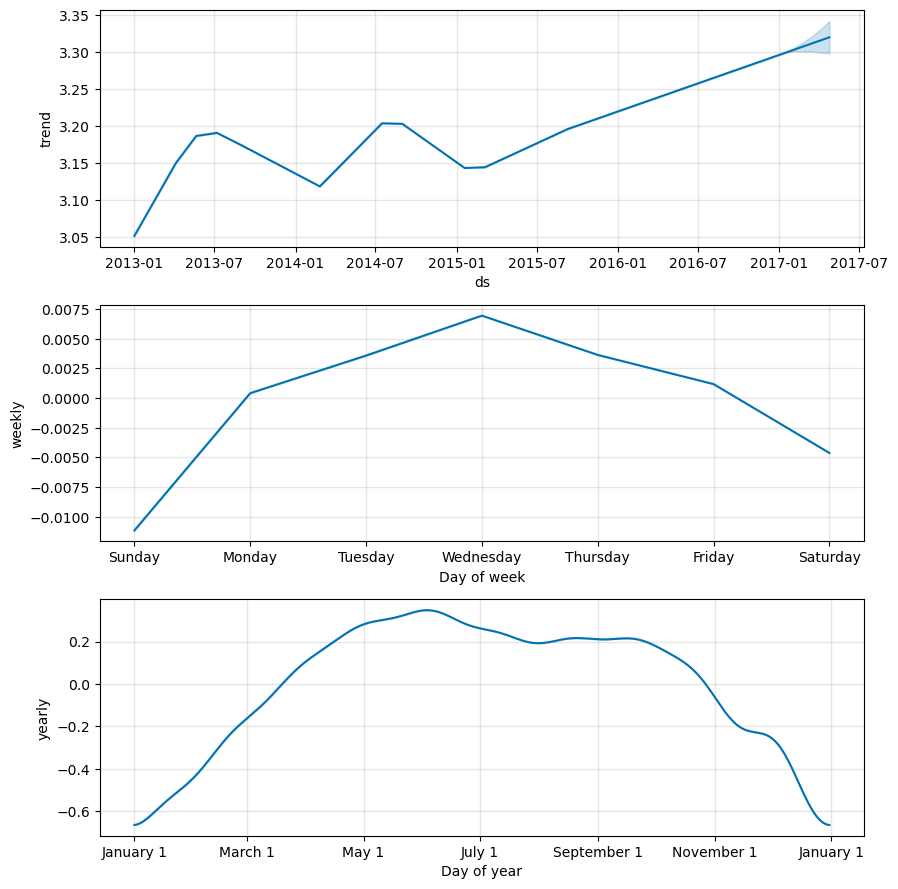

In [7]:
model.plot_components(forecast_data)

In [8]:
forecast_data_orig=forecast_data
forecast_data_orig['yhat']=np.exp(forecast_data_orig['yhat'])
forecast_data_orig['yhat_lower']=np.exp(forecast_data_orig['yhat_lower'])
forecast_data_orig['yhat_upper']=np.exp(forecast_data_orig['yhat_upper'])

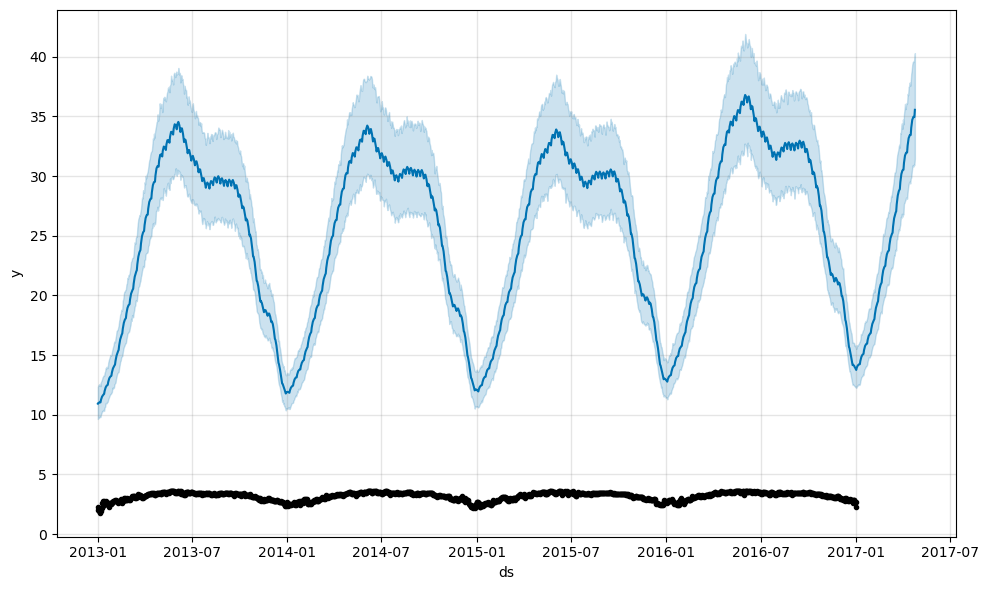

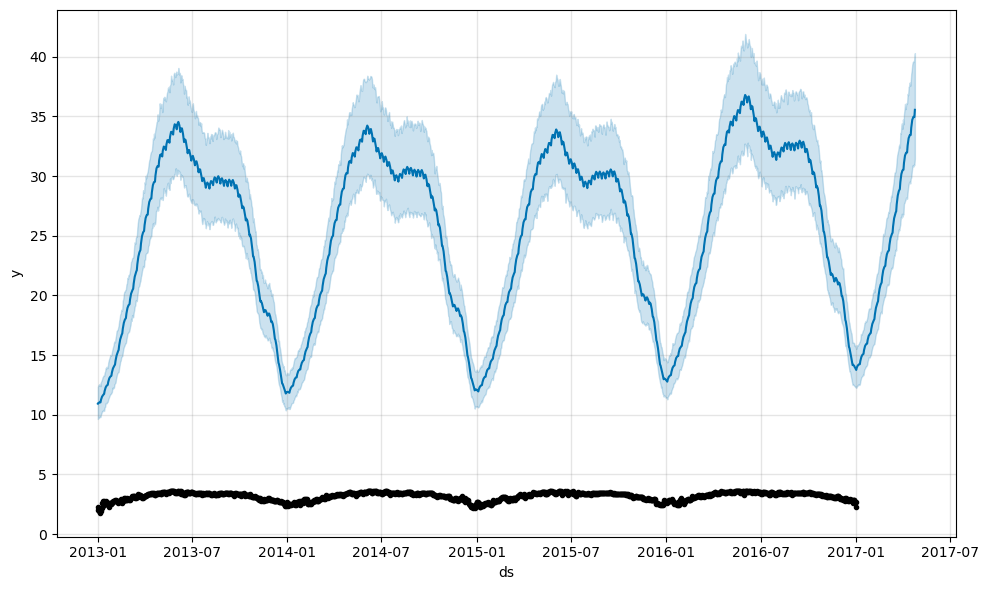

In [9]:
model.plot(forecast_data_orig)

In [10]:
final_df=pd.DataFrame(forecast_data_orig)
import plotly.graph_objs as go
import plotly.offline as py
actual_chart=go.Scatter(y=df_train['y_orig'],name='Actual')
predicted_chart=go.Scatter(y=final_df['yhat'],name='Predicted')
predicted_chart_upper=go.Scatter(y=final_df['yhat_upper'],name='Predicted Upper')
predicted_chart_lower=go.Scatter(y=final_df['yhat_lower'],name='predicted Lower')
py.plot([actual_chart,predicted_chart,predicted_chart_upper,predicted_chart_lower])

'temp-plot.html'

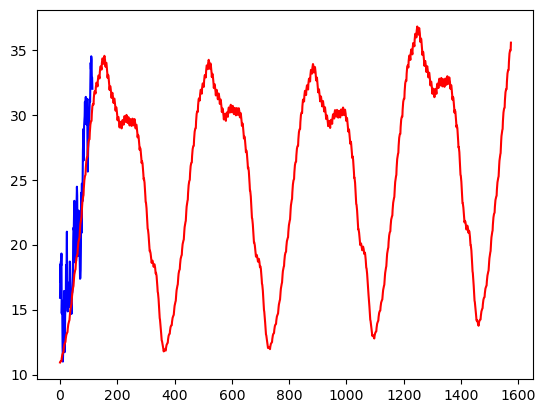

In [11]:
#let draw the graph for test data
rows=final_df['yhat']
plt.plot(df_test['meantemp'],color='blue')
plt.plot(rows,color='red')
plt.show()

## Multivarite analysis

In [12]:
df_train.head()
df_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   ds            1462 non-null   object 
 1   y             1462 non-null   float64
 2   humidity      1462 non-null   float64
 3   wind_speed    1462 non-null   float64
 4   meanpressure  1462 non-null   float64
 5   y_orig        1462 non-null   float64
dtypes: float64(5), object(1)
memory usage: 68.7+ KB


In [13]:
model_new=Prophet()
model_new.add_regressor('humidity')
model_new.add_regressor('wind_speed')
model_new.add_regressor('meanpressure')

In [14]:
model_new.fit(df_train)

00:24:48 - cmdstanpy - INFO - Chain [1] start processing
00:24:48 - cmdstanpy - INFO - Chain [1] done processing


In [15]:
future_data=model_new.make_future_dataframe(periods=113,freq='D')

In [17]:
df=pd.concat([df, df_test], ignore_index=True)
df = df.rename(columns={'meantemp': 'y', 'date':'ds'})
future_data=df[['ds', 'humidity', 'wind_speed', 'meanpressure']]

In [18]:
forecast_data = model_new.predict(future_data)

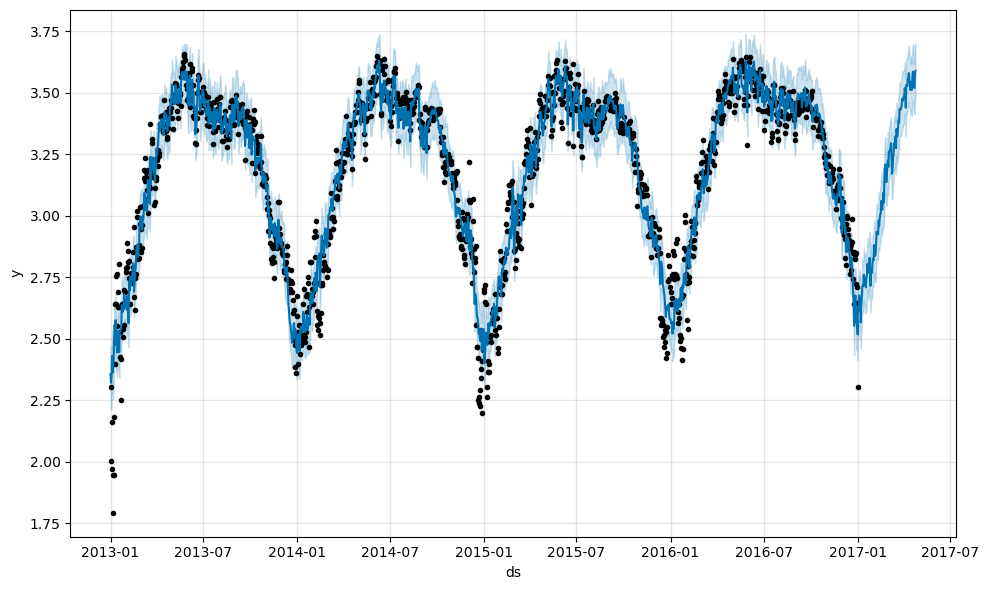

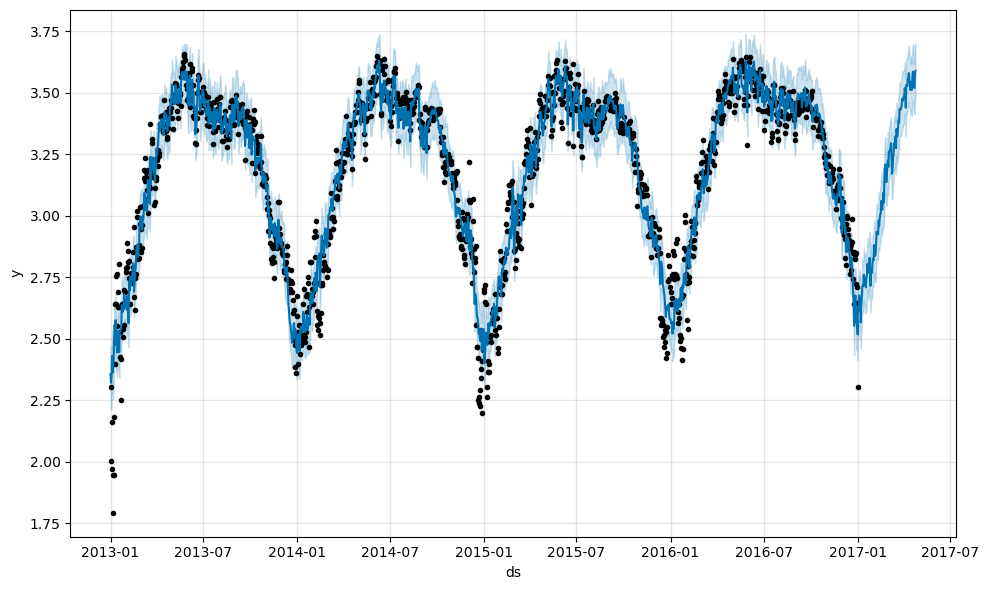

In [19]:
model_new.plot(forecast_data)

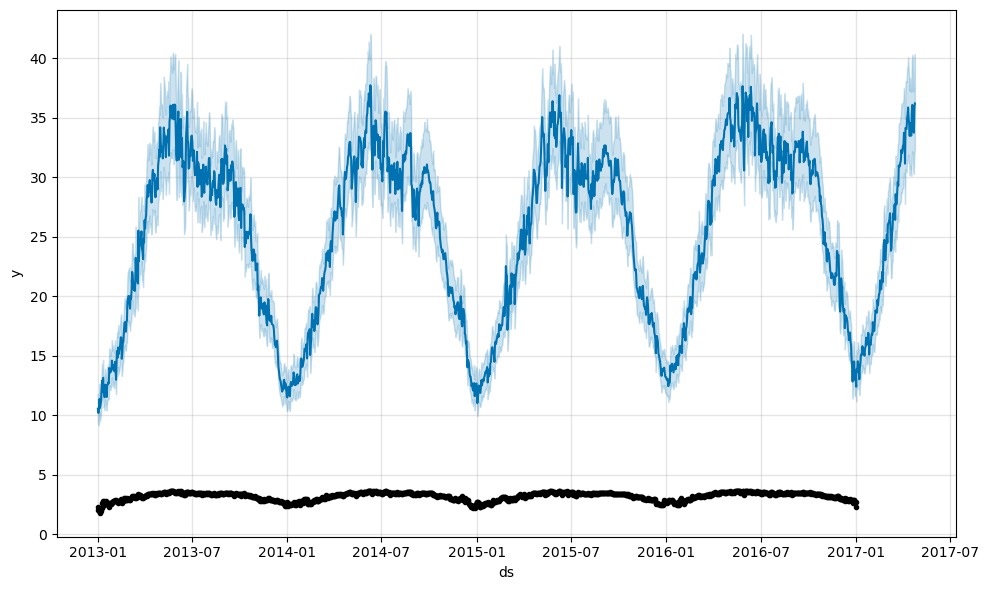

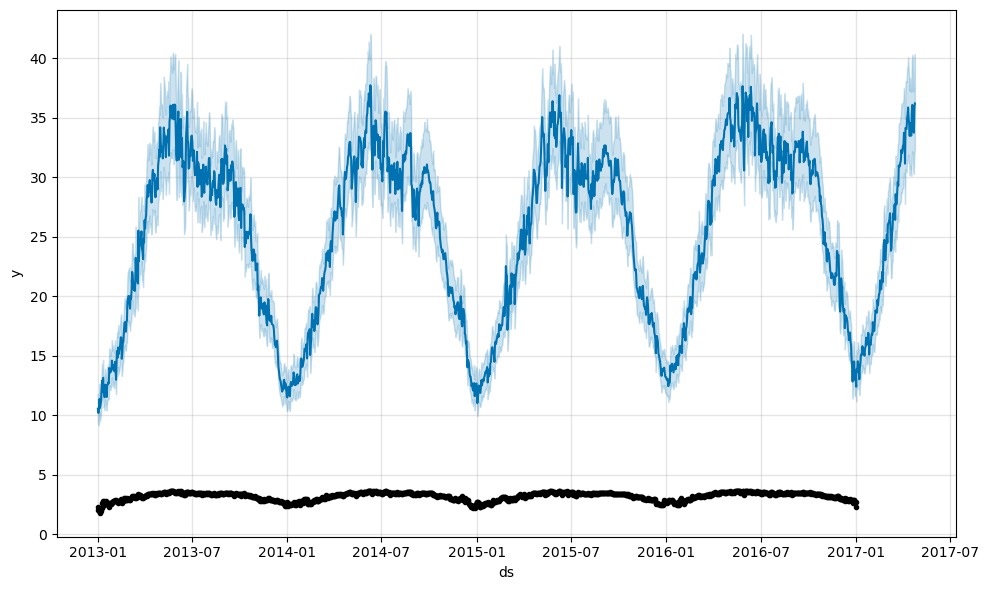

In [20]:
forecast_data_orig = forecast_data # make sure we save the original forecast data
forecast_data_orig['yhat'] = np.exp(forecast_data_orig['yhat'])
forecast_data_orig['yhat_lower'] = np.exp(forecast_data_orig['yhat_lower'])
forecast_data_orig['yhat_upper'] = np.exp(forecast_data_orig['yhat_upper'])

model_new.plot(forecast_data_orig)

In [21]:
final_df = pd.DataFrame(forecast_data_orig)
import plotly.graph_objs as go
import plotly.offline as py
#Plot predicted and actual line graph with X=dates, Y=Outbound
actual_chart = go.Scatter(y=df_train["y_orig"], name= 'Actual')
predict_chart = go.Scatter(y=final_df["yhat"], name= 'Predicted')
predict_chart_upper = go.Scatter(y=final_df["yhat_upper"], name= 'Predicted Upper')
predict_chart_lower = go.Scatter(y=final_df["yhat_lower"], name= 'Predicted Lower')
py.plot([actual_chart, predict_chart, predict_chart_upper, predict_chart_lower])

'temp-plot.html'